# 02. Features, windows and splits

Turns the clean table from `01_data_cleaning.ipynb` into model inputs and targets.

There are two targets, both for the **next trading day** of a ticker:

| target | definition | used for |
|---|---|---|
| `target` | next-day log return | the **next close price**, `Close * exp(predicted return)` |
| `target_vol` | next-day `log(High / Low)`, the intraday range | the **next-day volatility** |

Prices are non-stationary, so the price forecast is built from a predicted return rather than predicted
directly. Log returns add over time and are comparable across tickers at different price levels. Each sample is
a window of the last 30 days of four scale-free features:

| feature | meaning |
|---|---|
| `log_ret` | the ticker's daily log return |
| `vol_dev` | log volume minus its own 60-day rolling mean (how unusual today's volume is) |
| `hl_range` | log(High / Low), an intraday volatility proxy |
| `mkt_ret` | equal-weighted mean log return of all tickers that day |

No feature uses a price level, so the model does not depend on how high a stock trades.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

from formative_1 import stock_data as sd

PROCESSED = Path("../data/processed")

## Features

In [2]:
clean = pl.read_parquet(PROCESSED / "clean.parquet")
featured = sd.add_features(clean)
featured.select("Ticker", "day", "Close", *sd.FEATURES, "target", "target_vol").head(5)

Ticker,day,Close,log_ret,vol_dev,hl_range,mkt_ret,target,target_vol
str,date,f64,f64,f64,f64,f64,f64,f64
"""AAPL""",2000-01-03,0.848323,null,null,0.101049,null,-0.088077,0.08917
"""AAPL""",2000-01-04,0.776801,-0.088077,null,0.08917,-0.036374,0.014527,0.070852
"""AAPL""",2000-01-05,0.788168,0.014527,null,0.070852,0.004024,-0.090514,0.118952
"""AAPL""",2000-01-06,0.719961,-0.090514,null,0.118952,-0.004597,0.046281,0.055994
"""AAPL""",2000-01-07,0.754065,0.046281,null,0.055994,0.028931,-0.017744,0.076179


In [3]:
featured.select(*sd.FEATURES, "target", "target_vol").null_count()

log_ret,vol_dev,hl_range,mkt_ret,target,target_vol
u32,u32,u32,u32,u32,u32
61,1769,0,34,61,61


Nulls are expected: the first row of each ticker has no return, `vol_dev` needs 30 days of volume
history, and the last row of each ticker has no next day. `make_windows` drops them.

### Distributions

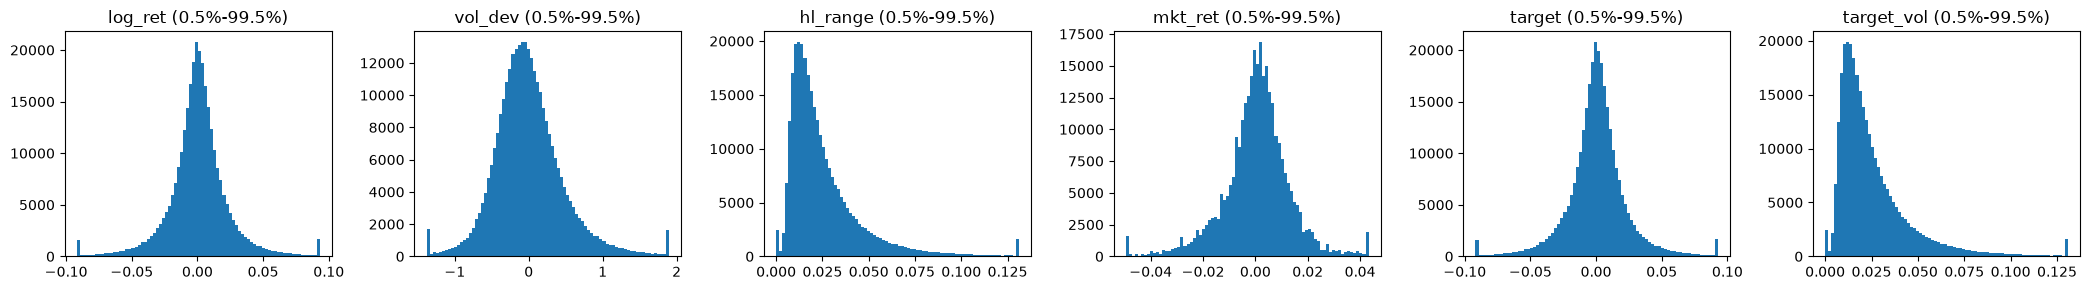

statistic,log_ret,vol_dev,hl_range,mkt_ret,target,target_vol
str,f64,f64,f64,f64,f64,f64
"""count""",303308.0,301600.0,303369.0,303335.0,303308.0,303308.0
"""null_count""",61.0,1769.0,0.0,34.0,61.0,61.0
"""mean""",0.000423,0.002239,0.025892,0.000423,0.000423,0.02588
"""std""",0.025414,0.497433,0.022124,0.013613,0.025414,0.022071
"""min""",-0.731248,-7.156535,0.0,-0.116108,-0.731248,0.0
"""25%""",-0.009756,-0.285605,0.012658,-0.005638,-0.009756,0.012657
"""50%""",0.000483,-0.041861,0.019673,0.001019,0.000483,0.019671
"""75%""",0.010792,0.238126,0.031903,0.007126,0.010792,0.031894
"""max""",0.618979,9.857137,2.179529,0.099085,0.618979,2.179529


In [4]:
cols = [*sd.FEATURES, "target", "target_vol"]
fig, axes = plt.subplots(1, 6, figsize=(21, 3))
for ax, col in zip(axes, cols):
    values = featured[col].drop_nulls()
    lo, hi = values.quantile(0.005), values.quantile(0.995)
    ax.hist(values.clip(lo, hi).to_numpy(), bins=80)
    ax.set_title(f"{col} (0.5%-99.5%)")
fig.tight_layout()
plt.show()
featured.select(*cols).describe()

### How much do the features say about the target?

Pooled correlation of each feature on day t with the next day's return. Daily returns are
close to unpredictable, so small values are expected. This sets the realistic ceiling for any
model.

In [5]:
corr = featured.drop_nulls(cols).select(
    [pl.corr(f, "target", method="spearman").alias(f) for f in sd.FEATURES]
)
display(Markdown("Spearman correlation with next-day log return:"))
corr

Spearman correlation with next-day log return:

log_ret,vol_dev,hl_range,mkt_ret
f64,f64,f64,f64
-0.021284,0.000841,0.00091,-0.010551


In [6]:
zero_mse = float((featured["target"].drop_nulls() ** 2).mean())
display(Markdown(f"""
**Baseline to beat.** Predicting a zero return every day gives an MSE of **{zero_mse:.6f}**.
The models in `03` and `04` are scored by how far below that they get (R² against zero).
"""))


**Baseline to beat.** Predicting a zero return every day gives an MSE of **0.000646**.
The models in `03` and `04` are scored by how far below that they get (R² against zero).


### The volatility target is more predictable

Unlike returns, the intraday range clusters: a wide-range day tends to follow a wide-range day. Below, the correlation of
tomorrow's range with today's features, and how a simple trailing average does as a forecast.

In [7]:
vol_frame = (
    featured.with_columns(
        abs_ret=pl.col("log_ret").abs(),
        hl_mean_5=pl.col("hl_range").rolling_mean(5).over("Ticker"),
        hl_mean_30=pl.col("hl_range").rolling_mean(30).over("Ticker"),
    )
    .drop_nulls(["target_vol", "hl_range", "vol_dev", "abs_ret", "hl_mean_5", "hl_mean_30"])
)
vol_corr = vol_frame.select(
    [pl.corr(f, "target_vol", method="spearman").alias(f) for f in ["hl_range", "hl_mean_5", "hl_mean_30", "abs_ret", "vol_dev", "mkt_ret"]]
)
display(Markdown("Spearman correlation with next-day `log(High/Low)`:"))
display(vol_corr)

mean_vol = float(vol_frame["target_vol"].mean())
base = {
    "predict the overall mean": float(((vol_frame["target_vol"] - mean_vol) ** 2).mean()),
    "today's range": float(((vol_frame["target_vol"] - vol_frame["hl_range"]) ** 2).mean()),
    "5-day mean range": float(((vol_frame["target_vol"] - vol_frame["hl_mean_5"]) ** 2).mean()),
    "30-day mean range": float(((vol_frame["target_vol"] - vol_frame["hl_mean_30"]) ** 2).mean()),
}
display(Markdown("MSE of simple volatility forecasts (all days, no model): " + ", ".join(f"{k} **{v:.2e}**" for k, v in base.items())))

Spearman correlation with next-day `log(High/Low)`:

hl_range,hl_mean_5,hl_mean_30,abs_ret,vol_dev,mkt_ret
f64,f64,f64,f64,f64,f64
0.709284,0.770122,0.764758,0.372698,0.140294,-0.072624


MSE of simple volatility forecasts (all days, no model): predict the overall mean **4.81e-04**, today's range **3.38e-04**, 5-day mean range **2.43e-04**, 30-day mean range **2.50e-04**

## Windows

`make_windows` builds one sample per ticker-day: the last 30 rows of the four features. `y` is the
next-day log return and `target_day` is the day being predicted.

In [8]:
X, y, target_day, y_vol = sd.make_windows(featured, extras=("target_vol",))
display(Markdown(f"`X` {X.shape} (samples, days, features), `y` (log return) and `y_vol` (next-day range) {y.shape}, {len(np.unique(target_day)):,} distinct target days."))

`X` (299770, 30, 4) (samples, days, features), `y` (log return) and `y_vol` (next-day range) (299770,), 6,349 distinct target days.

In [9]:
# Check one window against the raw rows it should come from
ticker = "AAPL"
frame = featured.filter(pl.col("Ticker") == ticker).drop_nulls(sd.FEATURES)
i = 100  # the 101st window of this ticker
expected = frame.select(sd.FEATURES).to_numpy()[i : i + sd.WINDOW]
expected_target = frame["target"][i + sd.WINDOW - 1]
expected_day = frame["day"][i + sd.WINDOW]  # the day after the window's last row

aapl_first = int(np.flatnonzero(np.all(np.isclose(X[:, 0], expected[0]), axis=1) & np.isclose(y, expected_target))[0])
assert np.allclose(X[aapl_first], expected)
assert target_day[aapl_first] == np.datetime64(expected_day)
display(Markdown(f"Window {aapl_first} matches AAPL rows {frame['day'][i]} to {frame['day'][i + sd.WINDOW - 1]} and predicts {expected_day}."))

Window 100 matches AAPL rows 2000-07-07 to 2000-08-17 and predicts 2000-08-18.

## Chronological split

Samples are split by the date of their **target**: train before 2019, validation 2019 to 2021,
test from 2022. There is no shuffling, and the model never sees a target that falls after its
split's cutoff.

In [10]:
train, val, test = sd.split_masks(target_day)

assert target_day[train].max() < np.datetime64(sd.VAL_START)
assert target_day[val].min() >= np.datetime64(sd.VAL_START) and target_day[val].max() < np.datetime64(sd.TEST_START)
assert target_day[test].min() >= np.datetime64(sd.TEST_START)
assert (train | val | test).all() and not (train & val).any() and not (val & test).any()

pl.DataFrame(
    {
        "split": ["train", "val", "test"],
        "samples": [int(m.sum()) for m in (train, val, test)],
        "first_target_day": [str(target_day[m].min()) for m in (train, val, test)],
        "last_target_day": [str(target_day[m].max()) for m in (train, val, test)],
        "return_std": [float(y[m].std()) for m in (train, val, test)],
        "vol_mean": [float(y_vol[m].mean()) for m in (train, val, test)],
    }
)

split,samples,first_target_day,last_target_day,return_std,vol_mean
str,i64,str,str,f64,f64
"""train""",204210,"""2000-03-28""","""2018-12-31""",0.024149,0.025044
"""val""",43031,"""2019-01-02""","""2021-12-31""",0.026391,0.026098
"""test""",52529,"""2022-01-03""","""2025-07-03""",0.027824,0.027566


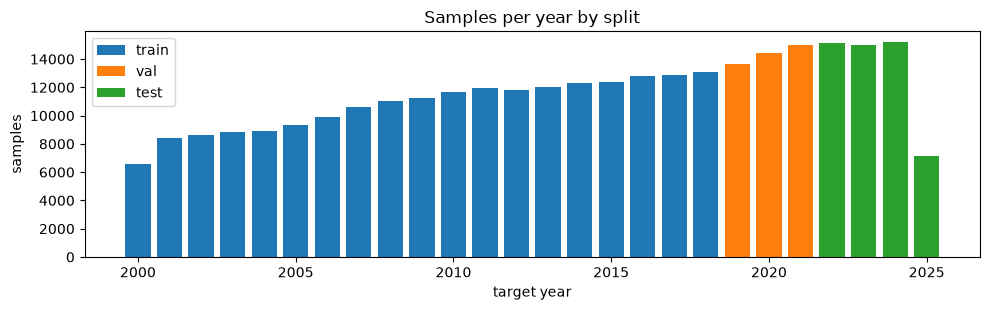

In [11]:
years = target_day.astype("datetime64[Y]").astype(int) + 1970
fig, ax = plt.subplots(figsize=(10, 3.2))
for name, mask in [("train", train), ("val", val), ("test", test)]:
    uniq, counts = np.unique(years[mask], return_counts=True)
    ax.bar(uniq, counts, label=name)
ax.set(title="Samples per year by split", xlabel="target year", ylabel="samples")
ax.legend()
fig.tight_layout()
plt.show()

The target's standard deviation differs between splits (table above), which is why validation and
test scores are reported relative to the zero baseline.

## Scaling

Features are standardised with **training-set** statistics only, so nothing about the validation
or test periods leaks into the inputs. The target is divided by the training standard deviation.

In [12]:
mean = X[train].mean(axis=(0, 1))
std = X[train].std(axis=(0, 1))
y_std = float(y[train].std())
vol_std = float(y_vol[train].std())
Xs = (X - mean) / std

pl.DataFrame(
    {
        "feature": sd.FEATURES,
        "train_mean": mean,
        "train_std": std,
        "scaled_mean_train": Xs[train].mean(axis=(0, 1)),
        "scaled_mean_val": Xs[val].mean(axis=(0, 1)),
        "scaled_mean_test": Xs[test].mean(axis=(0, 1)),
        "scaled_std_test": Xs[test].std(axis=(0, 1)),
    }
)

feature,train_mean,train_std,scaled_mean_train,scaled_mean_val,scaled_mean_test,scaled_std_test
str,f32,f32,f32,f32,f32,f32
"""log_ret""",0.000452,0.024246,1.7994e-8,0.017907,-0.022466,1.14941
"""vol_dev""",0.004312,0.499513,4.5581e-8,-0.016777,-0.004651,0.967834
"""hl_range""",0.0251,0.021476,0.00001,0.054373,0.119775,0.988379
"""mkt_ret""",0.00045,0.012962,1.7783e-7,0.034789,-0.042096,1.160245


In [13]:
display(Markdown(f"Target scales: return `y_std` = {y_std:.5f}, volatility `vol_std` = {vol_std:.5f}. Extreme scaled values (|z| > 20) per feature: " + ", ".join(
    f"{f} {int((np.abs(Xs[..., k]) > 20).sum()):,}" for k, f in enumerate(sd.FEATURES)
)))

Target scales: return `y_std` = 0.02415, volatility `vol_std` = 0.02135. Extreme scaled values (|z| > 20) per feature: log_ret 210, vol_dev 0, hl_range 420, mkt_ret 0

In [14]:
featured.write_parquet(PROCESSED / "features.parquet")
print(f"saved {featured.height:,} rows to {PROCESSED / 'features.parquet'}")

saved 303,369 rows to ../data/processed/features.parquet
